#1. Case study: Eniac’s A/B Test

Four versions of the button were taken for testing:

A - White “SHOP NOW”

B - Red “SHOP NOW”

C - White “SEE DEALS”

D - Red “SEE DEALS”

Metric chosen included

**Click-through rate (CTR) for the homepage.**

CTR = Total number of clicks / total visits to the page.

Selected as a measure of the initial ability of a website element to lead use to interact with it.

**Drop-off rate for the linked page.**

* represents the percentage of visitors who initiate a conversion process (such as a purchase or sign-up) but do not complete it.

* serves as an indicator of how engaged users remain at any point in the conversion process.

* A lower drop-off rate is preferable, as it suggests a higher likelihood of users completing the desired action.

**Homepage-return rate (HRR) for the category pages.**

* Measures how often users return to the homepage after clicking the button.

* Similarly to the drop-off rate, this metric helps us infer whether users are finding what they need after clicking the tested element.

* If they frequently return to the homepage, it suggests they might not be finding the desired information on the linked page.

* HRR serves as a useful indicator of how well the button leads users to the desired content.

* Ideally, we want to minimize the homepage-return rate, which would indicate that users are finding what they need on the first try.








In [18]:
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
#from scipy.stats import chi2
from itertools import combinations
from scipy.stats import chi2_contingency
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 120)

In [3]:
# version A.csv
url = "https://drive.google.com/file/d/1sbdZtK6Ib6g2nEk2unTts1pVKVNqVwNI/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
version_A = pd.read_csv(path)

# version B.csv
url = "https://drive.google.com/file/d/1QGOErY_5iukwS46ZwrBvA0sOzimzzJoX/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
version_B = pd.read_csv(path)

# version C.csv
url = "https://drive.google.com/file/d/1qq40NMj2NDeBFB7bogpZOo9YetbeiLAJ/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
version_C = pd.read_csv(path)

# version D.csv
url = "https://drive.google.com/file/d/1xGUsLyucAUVKtRAzRjo0cqq290LdHaeX/view?usp=drive_link"
path = "https://drive.google.com/uc?export=download&id="+url.split("/")[-2]
version_D = pd.read_csv(path)
version_A_copy = version_A.copy()
version_B_copy = version_B.copy()
version_C_copy = version_C.copy()
version_D_copy = version_D.copy()

In [4]:
version_A_copy = version_A.copy()
version_A_copy

,Element ID,Tag name,Name,No. clicks,Visible?,Snapshot information
0,48,h1,ENIAC,269,True,Homepage Version A - white SHOP NOW • https://eniac.com/index-a.php
1,25,div,mySidebar,309,True,"created 2021-09-14 • 14 days 0 hours 34 mins • 25326 visits, 23174 clicks"
2,4,a,Mac,279,True,NaN
3,69,a,iPhone,246,True,NaN
4,105,a,Accessories,1235,True,NaN
5,36,a,Chargers & Cables,1261,False,NaN
6,99,a,iPhone Accessories,1226,False,NaN
7,68,a,Watch Accessories,1261,False,NaN
8,13,a,Mac Accessories,1308,False,NaN
9,15,a,AirTag,206,False,NaN


In [ ]:
version_B_copy = version_B.copy()
version_B_copy

,Element ID,Tag name,Name,No. clicks,Visible?,Snapshot information
0,48,h1,ENIAC,236,True,Homepage Version B - red SHOP NOW • https:...
1,25,div,mySidebar,304,True,created 2021-10-27 • 14 days 0 hours 34 mi...
2,4,a,Mac,268,True,NaN
3,69,a,iPhone,260,True,NaN
4,105,a,Accessories,1214,True,NaN
5,36,a,Chargers & Cables,1259,False,NaN
6,99,a,iPhone Accessories,1237,False,NaN
7,68,a,Watch Accessories,1221,False,NaN
8,13,a,Mac Accessories,1210,False,NaN
9,15,a,AirTag,195,False,NaN


In [29]:
version_C_copy = version_C.copy()
version_C_copy

,Element ID,Tag name,Name,No. clicks,Visible?,Snapshot information
0,48,h1,ENIAC,288,True,Homepage Version C - white SEE DEALS • https://eniac.com/index-c.php
1,25,div,mySidebar,283,True,"created 2021-10-27 • 14 days 0 hours 34 mins • 24876 visits, 23031 clicks"
2,4,a,Mac,262,True,NaN
3,69,a,iPhone,234,True,NaN
4,105,a,Accessories,1288,True,NaN
5,36,a,Chargers & Cables,1224,False,NaN
6,99,a,iPhone Accessories,1175,False,NaN
7,68,a,Watch Accessories,1264,False,NaN
8,13,a,Mac Accessories,1203,False,NaN
9,15,a,AirTag,202,False,NaN


In [30]:
version_D_copy = version_D.copy()
version_D_copy

,Element ID,Tag name,Name,No. clicks,Visible?,Snapshot information
0,48,h1,ENIAC,285,True,Homepage Version D - red SEE DEALS • https://eniac.com/index-d.php
1,25,div,mySidebar,305,True,"created 2021-10-27 • 14 days 0 hours 34 mins • 25233 visits, 22743 clicks"
2,4,a,Mac,274,True,NaN
3,69,a,iPhone,243,True,NaN
4,105,a,Accessories,1267,True,NaN
5,36,a,Chargers & Cables,1260,False,NaN
6,99,a,iPhone Accessories,1296,False,NaN
7,68,a,Watch Accessories,1252,False,NaN
8,13,a,Mac Accessories,1273,False,NaN
9,15,a,AirTag,201,False,NaN


Extract Click Data
The dataset contains multiple tracked elements, so we need to filter only the main CTA buttons used in the experiment.

* Version A → White "SHOP NOW"
* Version B → Red "SHOP NOW"
* Version C → White "SEE DEALS"
* Version D → Red "SEE DEALS"

The number of clicks for each main button is extracted and will be used for CTR and Chi-Square analysis.

In [5]:
#check how many click are there
eniac_a_clicks= version_A_copy.loc[version_A_copy["Name"]=='SHOP NOW',"No. clicks"].iloc[0]
eniac_b_clicks= version_B_copy.loc[version_B_copy['Name']=='SHOP NOW', "No. clicks"].iloc[0]
eniac_c_clicks= version_C_copy.loc[version_C_copy["Name"]=='SEE DEALS',"No. clicks"].iloc[0]
eniac_d_clicks= version_D_copy.loc[version_D_copy['Name']=='SEE DEALS',"No. clicks"].iloc[0]

eniac_a_clicks, eniac_b_clicks, eniac_a_clicks, eniac_d_clicks

(np.int64(512), np.int64(281), np.int64(512), np.int64(193))

In [6]:
version_A_copy.iloc[1,-1]

'created 2021-09-14   •   14 days 0 hours 34 mins   •   25326 visits, 23174 clicks'

In [ ]:
version_B_copy.iloc[1,-1]

'created 2021-10-27   •   14 days 0 hours 34 mins   •   24747 visits, 22407 clicks'

In [ ]:
version_C_copy.iloc[1,-1]

'created 2021-10-27   •   14 days 0 hours 34 mins   •   24876 visits, 23031 clicks'

In [ ]:
version_D_copy.iloc[1,-1]

'created 2021-10-27   •   14 days 0 hours 34 mins   •   25233 visits, 22743 clicks'

In [7]:
# check the visitor for every version
eniac_a_visit= 25326
eniac_b_visit= 24747
eniac_c_visit= 24876
eniac_d_visit= 25233

From the above information, we can calculate the number of visitors who didn't click on the button

In [9]:
eniac_a_no_click= eniac_a_visit-eniac_a_clicks
eniac_b_no_click= eniac_b_visit-eniac_b_clicks
eniac_c_no_click= eniac_c_visit-eniac_c_clicks
eniac_d_no_click= eniac_d_visit-eniac_d_clicks

In [10]:
clicks = [eniac_a_clicks, eniac_b_clicks, eniac_c_clicks, eniac_d_clicks]
noclicks = [eniac_a_no_click, eniac_b_no_click, eniac_c_no_click, eniac_d_no_click]

observed_results = pd.DataFrame(data = [clicks, noclicks],
                                columns = ["Version_A", "Version_B", "Version_C", "Version_D"],
                                index = ["Click", "No-click"])

observed_results

,Version_A,Version_B,Version_C,Version_D
Click,512,281,527,193
No-click,24814,24466,24349,25040


In [11]:
import pandas as pd

data = {
    'version': ['C', 'A', 'B', 'D'],
    'button': ['White SEE DEALS', 'White SHOP NOW', 'Red SHOP NOW', 'Red SEE DEALS'],
    'clicks': [527, 512, 281, 193],
    'visitors': [24876, 25326, 24747, 25233]
}

ctr_df = pd.DataFrame(data)

ctr_df['ctr'] = ctr_df['clicks'] / ctr_df['visitors']
ctr_df['ctr_percent'] = ctr_df['ctr'] * 100

ctr_df = ctr_df.sort_values("ctr_percent", ascending=False)

ctr_df

,version,button,clicks,visitors,ctr,ctr_percent
0,C,White SEE DEALS,527,24876,0.021185,2.118508
1,A,White SHOP NOW,512,25326,0.020216,2.021638
2,B,Red SHOP NOW,281,24747,0.011355,1.135491
3,D,Red SEE DEALS,193,25233,0.007649,0.764871


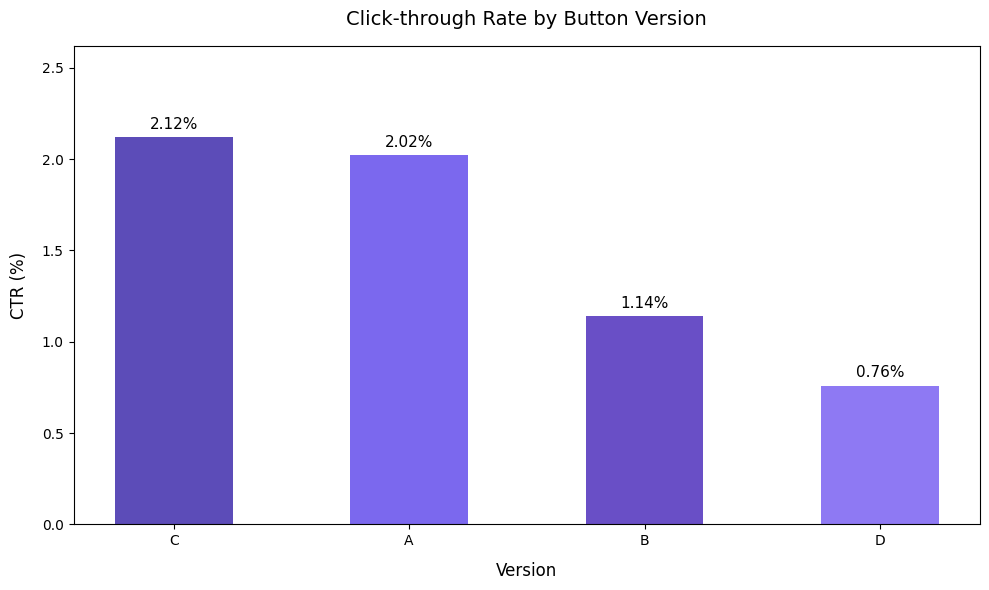

In [13]:
versions = []
ctr_values = []

for index, row in ctr_df.iterrows():
    versions.append(row['version'])
    ctr_values.append(round(row['ctr_percent'], 2))

# 3. Matplotlib diye Plot / Visualization toiri kora
plt.figure(figsize=(10, 6))

colors = ['#5c4cb8', '#7b68ee', '#694fc6', '#8e79f3']
bars = plt.bar(versions, ctr_values, color=colors, width=0.5)

# Title and Labels
plt.title('Click-through Rate by Button Version', fontsize=14, pad=15)
plt.xlabel('Version', fontsize=12, labelpad=10)
plt.ylabel('CTR (%)', fontsize=12, labelpad=10)


plt.ylim(0, max(ctr_values) + 0.5)
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2, height + 0.03, f"{height:.2f}%",
             ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()

## Overall Chi-Square Test

The chi-square test checks whether the observed click-through differences across the four versions are statistically significant.

Null hypothesis: all button versions have the same click-through rate.
Alternative hypothesis: at least one button version has a different click-through rate.

Significance level: α = 0.05

In [15]:
# Overall chi-square test

alpha = 0.05

chi2_stat, p_value, dof, expected = stats.chi2_contingency(observed_results)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"Degrees of freedom: {dof}")
print(f"p-value: {p_value:.10f}")

if p_value < alpha:
    print("\nDecision: Reject the null hypothesis.")
    print("at least one of the four different versions performed significantly better or worse than the others.")
else:
    print("\nDecision: Fail to reject the null hypothesis.")
    print("There is not enough evidence to conclude that the versions perform differently.")

Chi-square statistic: 224.0188
Degrees of freedom: 3
p-value: 0.0000000000

Decision: Reject the null hypothesis.
at least one of the four different versions performed significantly better or worse than the others.


## Post-Hoc Pairwise Tests

The overall chi-square test shows that a difference exists, but it does not show which specific versions differ.

To compare each pair of versions, pairwise chi-square tests are used.

There are six pairwise comparisons, so a Bonferroni correction is applied:

Adjusted α = 0.05 / 6 = 0.0083

In [19]:
# 1. Generate all pairs of versions
versions = observed_results.columns.tolist()
pairs = list(combinations(versions, 2))

# Calculate adjusted alpha for Bonferroni correction (0.05 / total number of comparisons)
alpha = 0.05
bonferroni_alpha = alpha / len(pairs)

results = []

# 2. Run Chi-Square test for each pair
for v1, v2 in pairs:
    # Extract the 2x2 contingency matrix
    sub_table = observed_results[[v1, v2]].values

    # Perform Chi-Square test
    chi2, p_val, _, _ = chi2_contingency(sub_table)

    # Clean version names for display (e.g., 'A vs B')
    comp_name = f"{v1.replace('Version_', '')} vs {v2.replace('Version_', '')}"

    results.append({
        'comparison': comp_name,
        'chi2': chi2,
        'p_value': p_val,
        'significant_after_bonferroni': p_val < bonferroni_alpha
    })

# 3. Create results DataFrame
pairwise_results = pd.DataFrame(results)

# Display results
pairwise_results


,comparison,chi2,p_value,significant_after_bonferroni
0,A vs B,62.493623,2.673088e-15,True
1,A vs C,0.534210,4.648421e-01,False
2,A vs D,144.283184,3.080898e-33,True
3,B vs C,74.229172,6.955480e-18,True
4,B vs D,17.876340,2.357337e-05,True
5,C vs D,161.117041,6.450501e-37,True


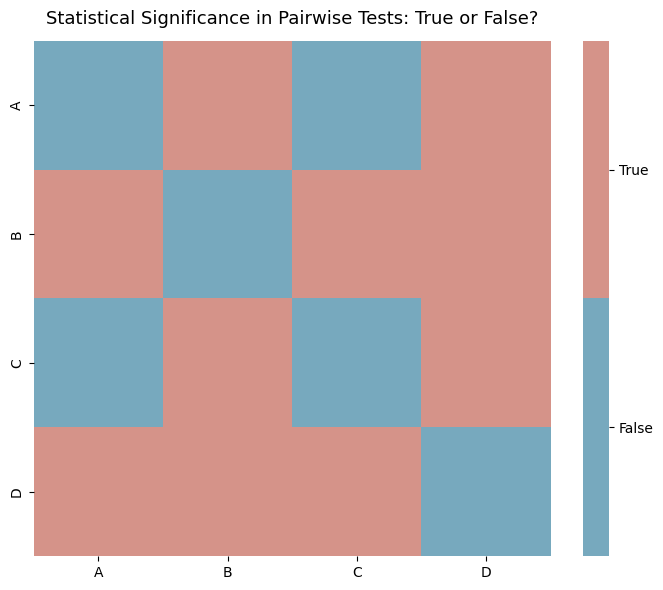

In [38]:
import matplotlib.pyplot as plt
import pandas as pd
from scipy import stats
import seaborn as sns

# 1. Calculate Bonferroni adjusted alpha to control for multiple testing bias
alpha = 0.05
num_comparisons = 6  # 4 * (4 - 1) / 2 total pairwise combinations
alpha_post_hoc = alpha / num_comparisons

# 2. Initialize dictionary to store boolean significance results
stat_significant_dict = {
    "Version_A": [],
    "Version_B": [],
    "Version_C": [],
    "Version_D": [],
}

# 3. Perform pairwise Chi-Square tests across all variant pairs
for i in observed_results.columns:
  for j in observed_results.columns:
    if i == j:
      # Comparing a version to itself is set to False
      stat_significant_dict[i].append(False)
    else:
      # Extract 2x2 contingency table for the current pair
      sub_table = observed_results.loc[:, [i, j]]
      chisq, pvalue, df, expected = stats.chi2_contingency(
          sub_table, correction=False
      )
      # Check if p-value is strictly lower than the Bonferroni threshold
      stat_significant_dict[i].append(pvalue < alpha_post_hoc)

# 4. Convert results into a square DataFrame with simplified labels
clean_labels = ['A', 'B', 'C', 'D']
stat_significant_df = pd.DataFrame(
    stat_significant_dict,
    index=clean_labels,
)
stat_significant_df.columns = clean_labels

# 5. Define two-tone color palette (Muted Blue for False, Soft Red for True)
palette = sns.color_palette(['#77a9be', '#d59389'])

# 6. Plot the pairwise significance heatmap
plt.figure(figsize=(7, 6))

ax = sns.heatmap(
    stat_significant_df.astype(int),
    cmap=palette,
    cbar=True,
    linewidths=0,  # Seamless cells without borders
)

# 7. Configure custom colorbar ticks and labels
colorbar = ax.collections[0].colorbar
colorbar.set_ticks([0.25, 0.75])
colorbar.set_ticklabels(['False', 'True'])

# 8. Set chart title and adjust layout
ax.set_title(
    'Statistical Significance in Pairwise Tests: True or False?',
    pad=12,
    fontsize=13,
)

plt.tight_layout()
plt.show()

In [39]:
stat_significant_df

,A,B,C,D
A,False,True,False,True
B,True,False,True,True
C,False,True,False,True
D,True,True,True,False


Analysing our heatmap, it is evident that the version with the highest click-through rate, **Version_C**, exhibits a statistically significant difference when compared **Versions B and D**, but not to **Version_A**, which possesses the second-highest click-through rate. As a result, declaring a clear winner based on post hoc tests becomes challenging, therefore we can only say that both **Version_C** and **Version_A** are the winners.

##Further Analysis with other metrics

After conducting the post-hoc tests, there is still no single clear winning variant.

The next steps could include running another experiment with the top-performing variants or analyzing additional metrics to better understand user behavior and make a more informed decision.

In this case, it was decided to examine drop-off rate and homepage return rate (as defined earlier). However, due to an error in the data collection process, these metrics were not available for Version B.

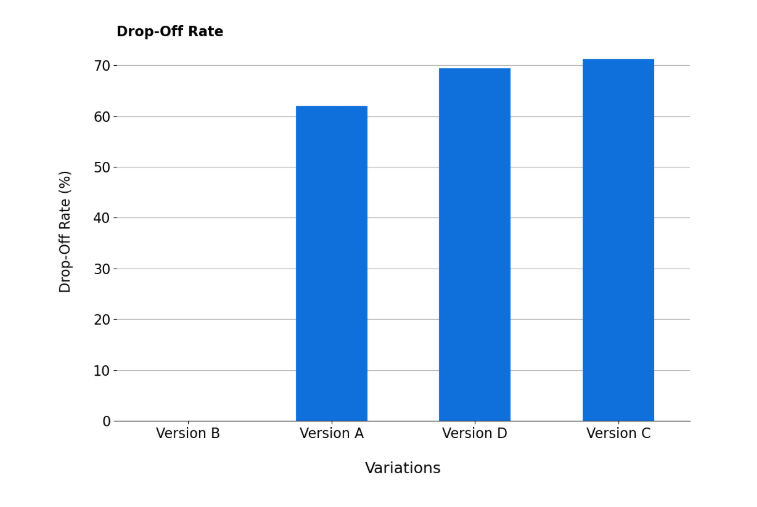

* Version A had the lowest Drop-off rate compared to D & C





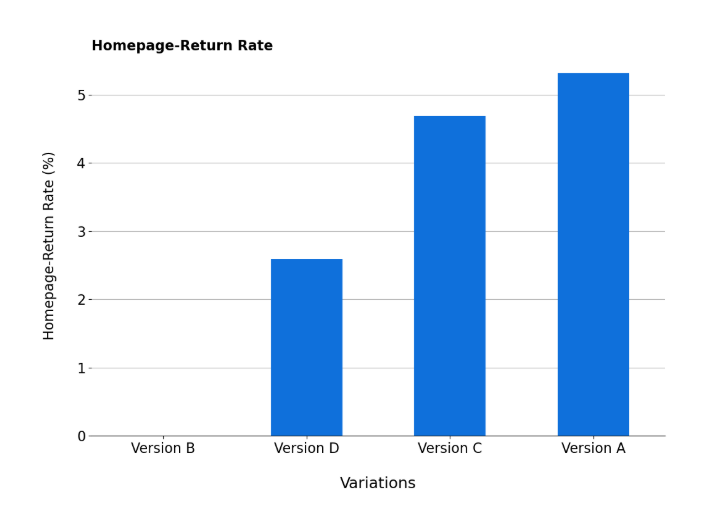


* Version D had the lowest Homepage return rate

##Observations

**Version A** seems to have high CTR (second to C with 2.02%), lower Drop-off rate (62%) but higher HRR (5.1%). Version A provides the best balance as it attracts a high volume of users and keeps them engaged better than other versions.

**Version C** achieves the highest CTR (2.12%) but also has the highest drop-off rate (71%) and a moderate homepage-return rate (4.8%). While it attracts the most clicks, it struggles to retain users through the conversion funnel, suggesting that the button generates interest but the post-click experience fails to meet expectations.

**Version D** has the lowest CTR (0.76%), higher Drop off rate (69%) & lowest HRR (2.7%).Version D is a "safe" bet for navigation, but its low volume makes it a poor choice for growth.



##Conclusions

if a definitive winner is required, additional steps need to be implemented. This is where we transition from the realm of statistics to the business world. The following actions can help in determining the version to be featured on the website in the future:

* Consider other metrics alongside click-through rate.
* Incorporate qualitative research findings.
* Seek input from subject-matter experts.
* Redesign the experiment and conduct it once more.



